In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# loading cleaned data 

df = pd.read_csv('../Dataset/wine_quality_cleaned.csv')

In [4]:
# viewing df details

print(df.shape)
display(df.info())

(5320, 13)
<class 'pandas.DataFrame'>
RangeIndex: 5320 entries, 0 to 5319
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         5320 non-null   float64
 1   volatile_acidity      5320 non-null   float64
 2   citric_acid           5320 non-null   float64
 3   residual_sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free_sulfur_dioxide   5320 non-null   float64
 6   total_sulfur_dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   int64  
 12  color                 5320 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 540.4 KB


None

In [5]:
# viewing transposed statistical analysis

df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000
volatile_acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000
citric_acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000
residual_sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100
free_sulfur_dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000
total_sulfur_dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000


In [6]:
# checking range of quality

df['quality'].value_counts()

quality
6    2323
5    1752
7     856
4     206
8     148
3      30
9       5
Name: count, dtype: int64

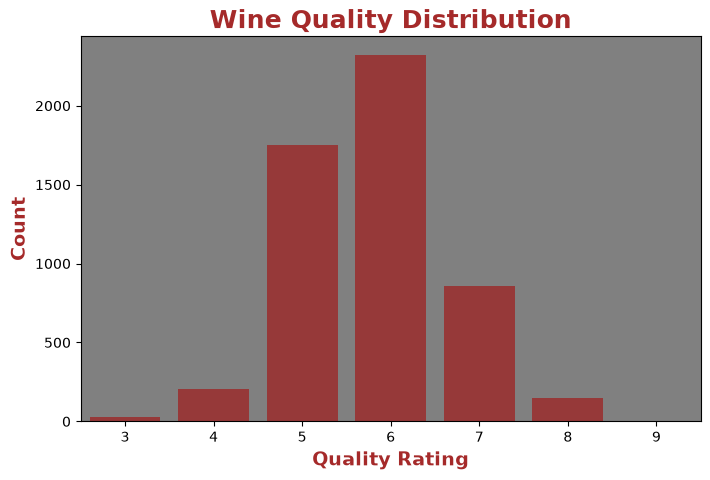

In [13]:
# wine quality distribution visualization 

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='quality',
    color='brown'
)

plt.gca().set_facecolor('grey')

plt.title('Wine Quality Distribution',
          fontsize=18,
          fontweight='bold',
          color='brown')

plt.xlabel('Quality Rating',
           fontsize=14,
           color='brown',
           fontweight='bold')

plt.ylabel('Count',
           fontsize=14,
           color='brown',
           fontweight='bold')

plt.savefig(
    r'../Report/Visualizations/wine_quality_distribution.png',
    dpi=120, # dot per inches
    bbox_inches='tight' # bounding box inches
    )
plt.show()

In [14]:
num_cols = df.select_dtypes(include=[np.number]).columns.to_list()
cat_cols = df.select_dtypes(include=['object', 'str']).columns.to_list()

print('Numerical Columns: ', num_cols)
print('Categorical Columns: ', cat_cols)

Numerical Columns:  ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Categorical Columns:  ['color']


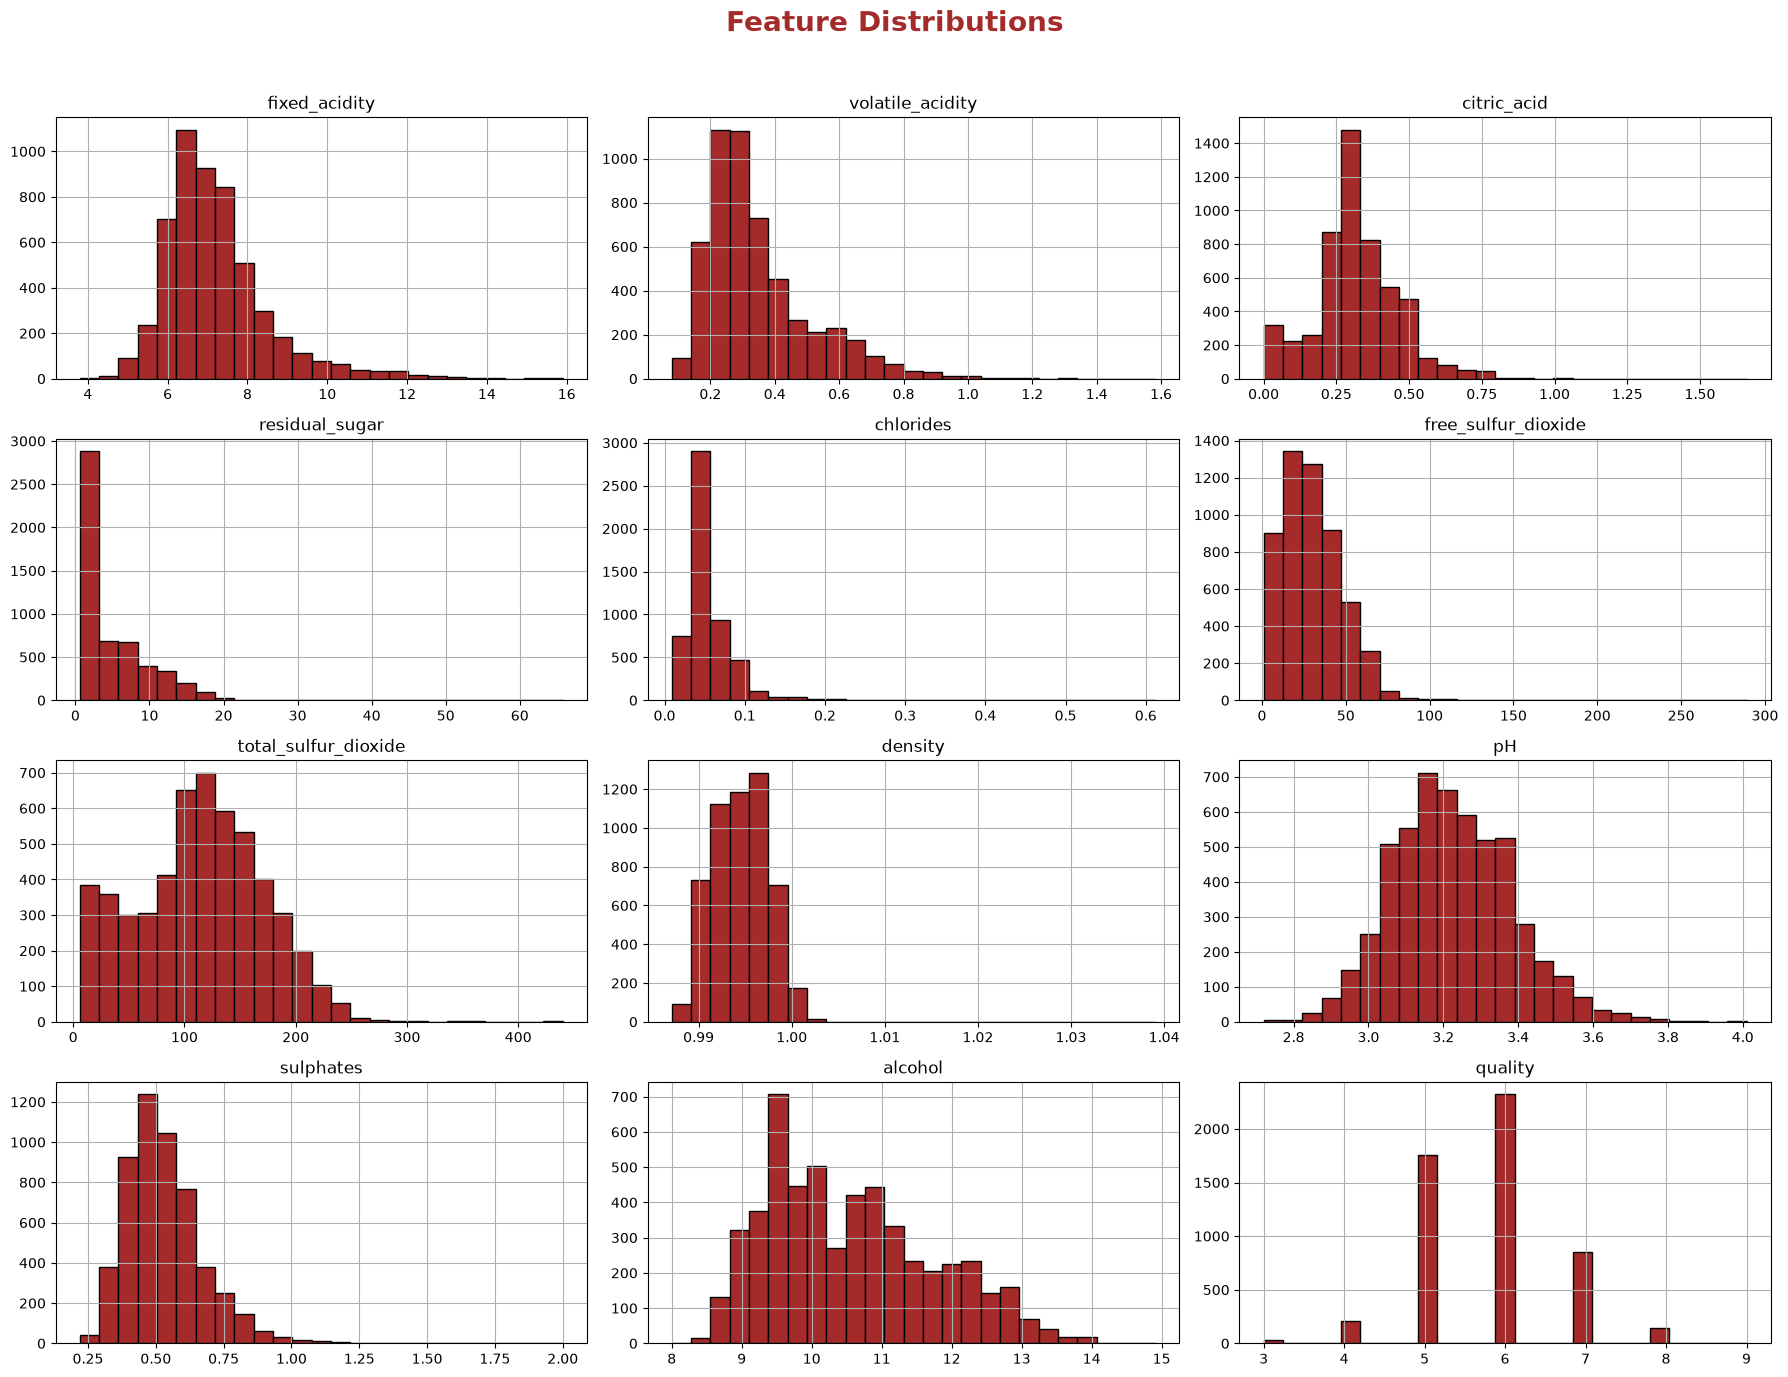

In [22]:
# visualizing feature distribution

df[num_cols].hist(
    bins=25,
    figsize=(18, 14),
    color='brown',
    edgecolor='black'
)

plt.suptitle(
    'Feature Distributions',
    fontsize=20,
    fontweight='bold',
    color='brown'
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    '../Report/Visualizations/feature_distribution.png',
    dpi=70,
    bbox_inches='tight'
)

plt.show()

In [23]:
skewness = df[num_cols].skew()

skewed_cols = skewness[skewness > 1].index.to_list()
unskewed_cols = skewness[skewness <= 1].index.to_list()

print('Skewed Columns: ', skewed_cols)
print('Unskewed Columns: ', unskewed_cols)

Skewed Columns:  ['fixed_acidity', 'volatile_acidity', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'sulphates']
Unskewed Columns:  ['citric_acid', 'total_sulfur_dioxide', 'density', 'pH', 'alcohol', 'quality']


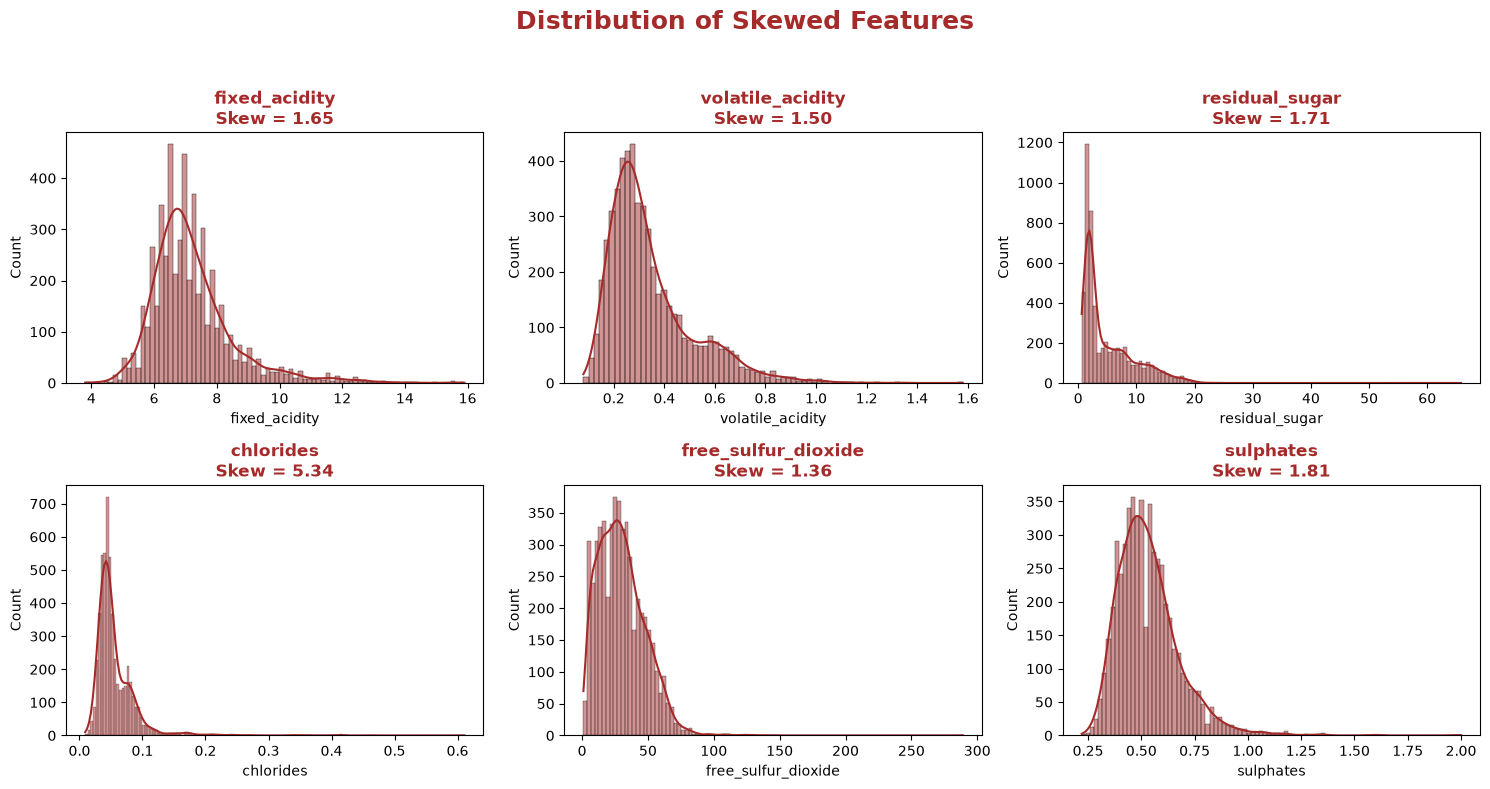

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for col, ax in zip(skewed_cols, axes):

    sns.histplot(
        df[col],
        kde=True,
        color='brown',
        edgecolor='black',
        ax=ax
    )

    ax.set_title(
        f'{col}\nSkew = {df[col].skew():.2f}',
        fontsize=12,
        fontweight='bold',
        color='brown'
    )


fig.suptitle(
    'Distribution of Skewed Features',
    fontsize=18,
    fontweight='bold',
    color='brown'
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    '../Report/Visualizations/skewed_columns_distribution.png',
    dpi=80,
    bbox_inches='tight'
)

plt.show()

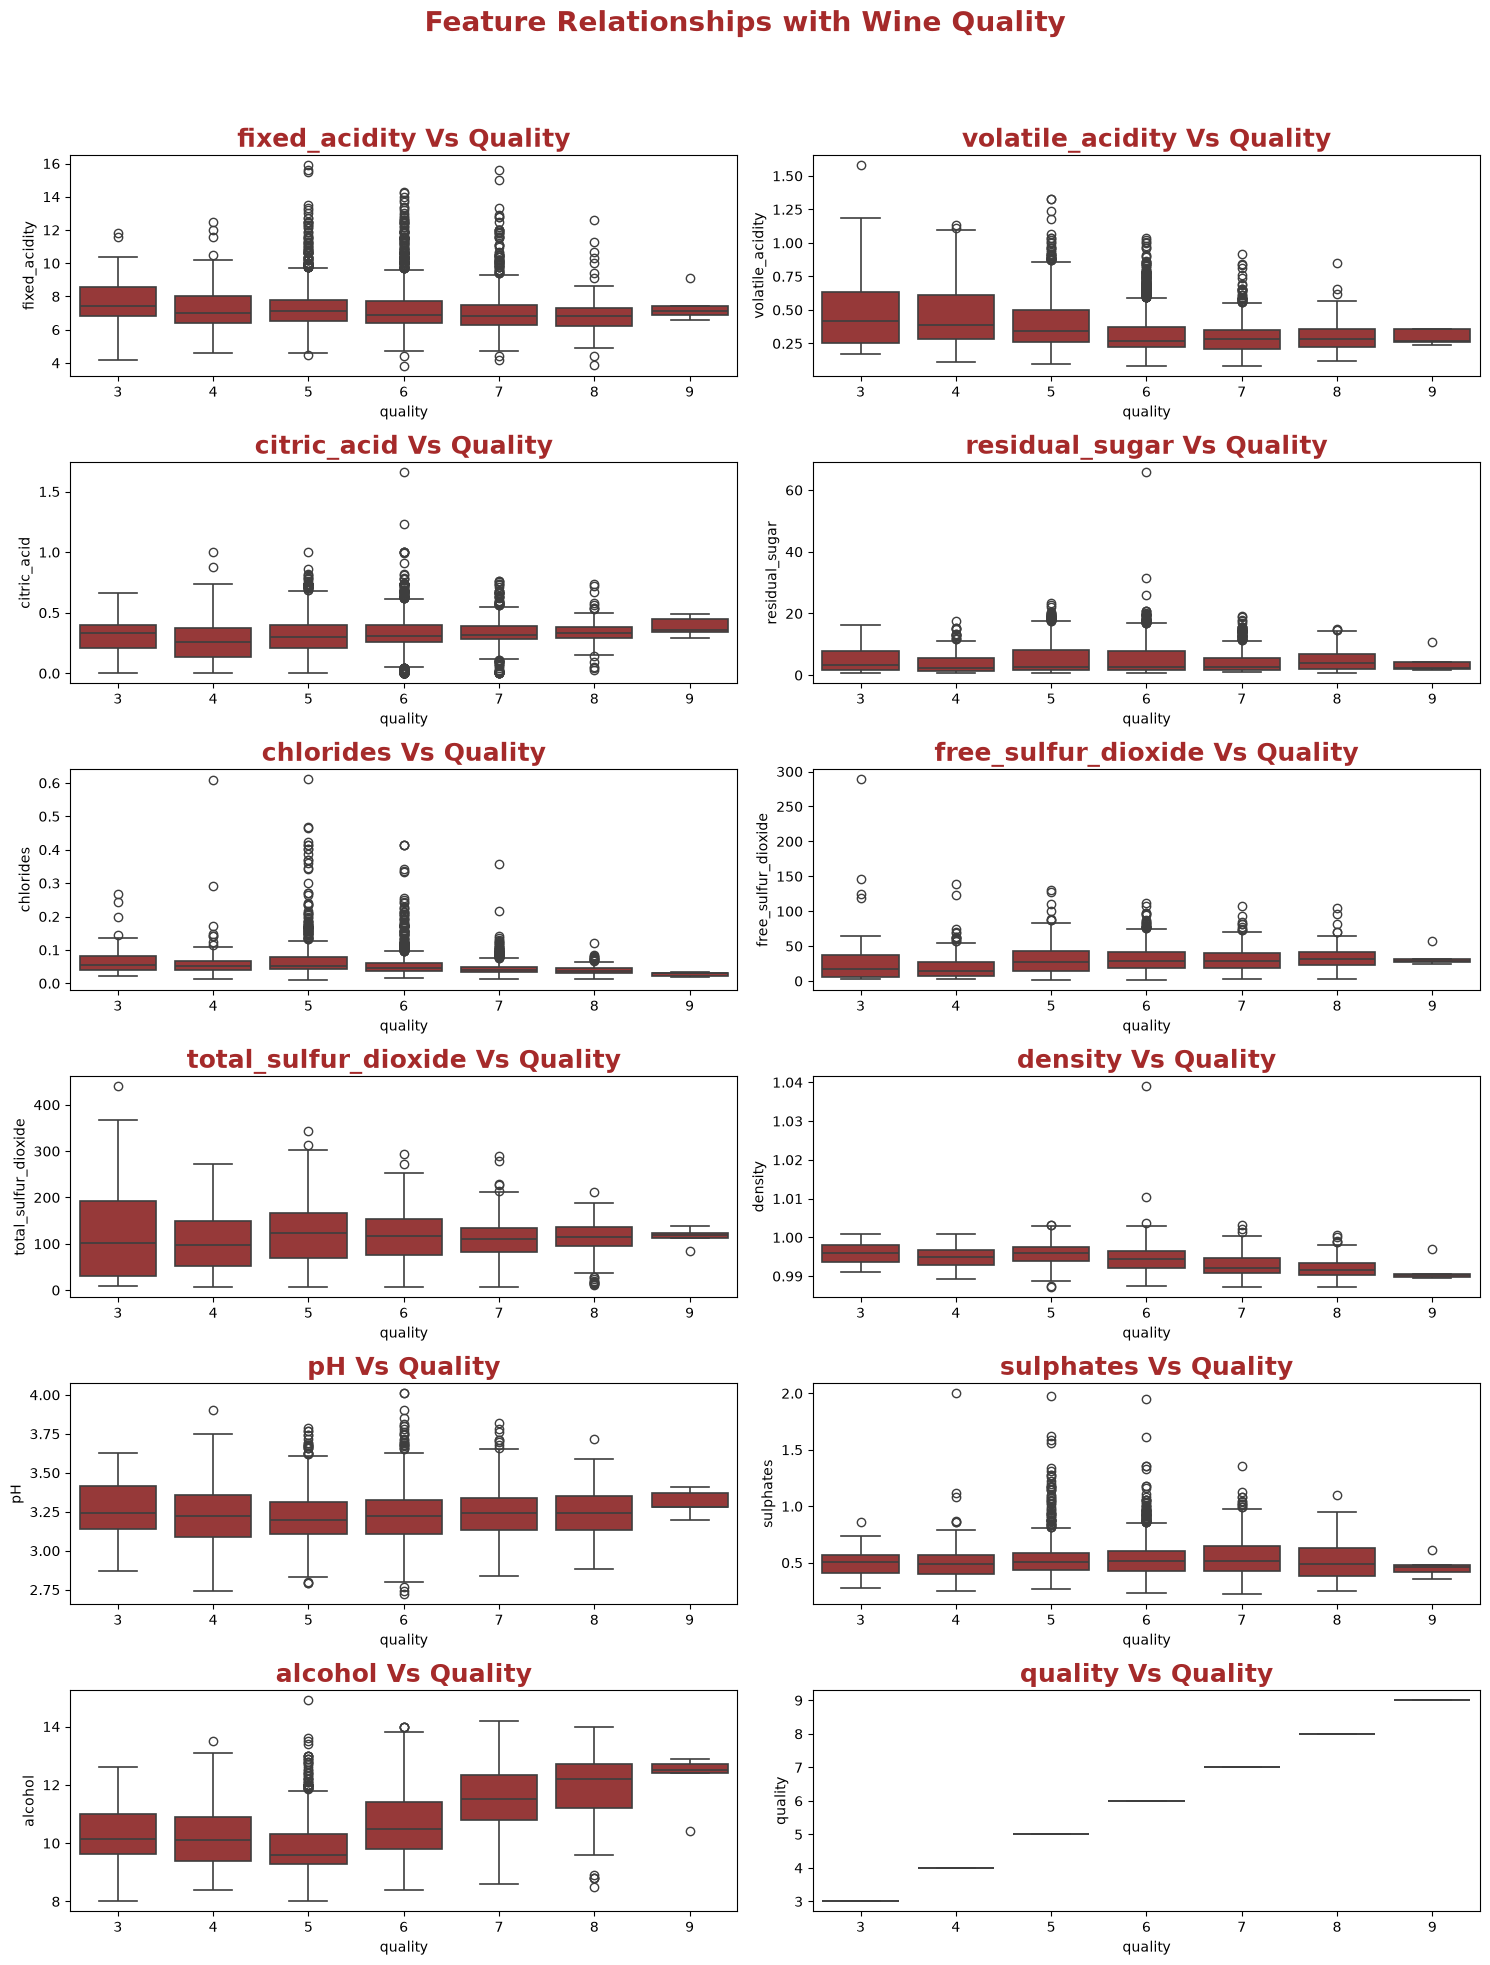

In [34]:
# visualized features relationship with quality

fig, axes = plt.subplots(6, 2, figsize=(15, 20))
axes = axes.flatten()

for col, ax in zip(num_cols, axes):
    sns.boxplot(
        data=df,
        x='quality',
        y=col,
        color='brown',
        linewidth=1.2,
        ax=ax
    )

    ax.set_title(
        f'{col} Vs Quality', 
        color='brown', 
        fontsize=18,
        fontweight='bold',
    )

plt.suptitle('Feature Relationships with Wine Quality',
    fontsize=20,
    fontweight='bold',
    color='brown'
    )    

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    '../Report/Visualizations/features_quality_relationship.png',
    dpi=80,
    bbox_inches='tight'
)
plt.show()